# Chapitre 14 - Exercices 14.1 à 14.6

Pondération des distances, algorithme EM et K-means, règles d'association généralisées par
arbres et PRIM, cartes auto-organisatrices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## Exercice 14.1 : Poids dans une distance euclidienne

**Énoncé.** On définit la distance euclidienne pondérée, de poids $w_l > 0$,

$$d_e^{(w)}(x_i, x_{i'}) = \frac{\sum_{l=1}^p w_l (x_{il} - x_{i'l})^2}{\sum_{l=1}^p w_l}.$$

Montrer que $d_e^{(w)}(x_i, x_{i'}) = d_e(z_i, z_{i'}) = \sum_{l=1}^p (z_{il} - z_{i'l})^2$
(éq. (14.112)) avec $z_{il} = x_{il}\,\big(w_l / \sum_{l'} w_{l'}\big)^{1/2}$ (éq. (14.113)) :
la distance pondérée sur $x$ est la distance usuelle sur des variables $z$ remises à l'échelle.

### Solution

Notons $W = \sum_{l'} w_{l'} > 0$ et $c_l = (w_l/W)^{1/2}$, de sorte que $z_{il} = c_l\, x_{il}$.
Pour chaque coordonnée $l$, par linéarité,

$$z_{il} - z_{i'l} = c_l\,(x_{il} - x_{i'l}) \quad\Longrightarrow\quad
(z_{il} - z_{i'l})^2 = c_l^2 (x_{il} - x_{i'l})^2 = \frac{w_l}{W}(x_{il} - x_{i'l})^2 .$$

En sommant sur $l$ :
$\sum_l (z_{il} - z_{i'l})^2 = \frac{1}{W}\sum_l w_l (x_{il} - x_{i'l})^2 = d_e^{(w)}(x_i, x_{i'})$.
$\square$

> **Conséquence pratique.** Tout algorithme fondé sur la distance euclidienne (K-means,
> classification hiérarchique…) appliqué avec des poids $w_l$ équivaut à l'algorithme
> **non pondéré** appliqué aux variables $z_l = c_l x_l$ : pondérer, c'est changer d'échelle.
> Par exemple les poids $w_l = 1/(2\,\mathrm{var}_l)$ correspondent à la standardisation.

### Vérification numérique

In [2]:
rng = np.random.RandomState(0)
X = rng.normal(size=(6, 4))
w = np.array([1.0, 4.0, 0.5, 2.0])
d_w = (w * (X[:, None, :] - X[None, :, :]) ** 2).sum(-1) / w.sum()
Z = X * np.sqrt(w / w.sum())
d_z = ns.distances_carrees(Z)
print("écart maximal entre les deux matrices : %.2e" % np.abs(d_w - d_z).max())

écart maximal entre les deux matrices : 1.78e-15


Les K-means « pondérés » (affectation selon $d_e^{(w)}$, centres = moyennes) donnent donc la
même partition que les K-means ordinaires sur $Z$ :

In [3]:
X2 = np.vstack([rng.normal(m, 1, size=(40, 2)) for m in ((0, 0), (0, 4), (6, 2))])
w2 = np.array([1.0, 9.0])
Z2 = X2 * np.sqrt(w2 / w2.sum())
lab_z, C_z, _ = ns.kmeans(Z2, 3, rng=np.random.RandomState(0))
C = C_z / np.sqrt(w2 / w2.sum())          # centres ramenés dans l'échelle de x
lab_w = ((w2 * (X2[:, None, :] - C[None]) ** 2).sum(-1)).argmin(1)
print("Partitions identiques :", np.array_equal(lab_z, lab_w))

Partitions identiques : True


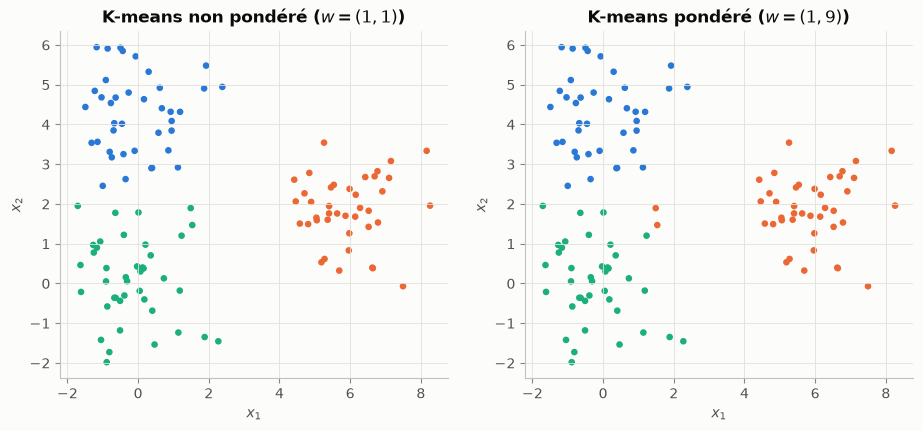

In [4]:
lab_x = ns.kmeans(X2, 3, rng=np.random.RandomState(0))[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, lab, titre in ((axes[0], lab_x, "K-means non pondéré ($w = (1, 1)$)"),
                       (axes[1], lab_w, "K-means pondéré ($w = (1, 9)$)")):
    ax.scatter(*X2.T, c=[COLORS[k] for k in lab], s=14)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(titre)
plt.show()

Le poids 9 sur $x_2$ revient à étirer l'axe vertical d'un facteur 3 : la partition change.

> **À retenir.** Pondérer la distance euclidienne équivaut à multiplier chaque variable par la
> racine de son poids normalisé ; le choix des poids est un choix d'échelle des variables.

## Exercice 14.2 : Algorithme EM pour un mélange gaussien isotrope et K-means

**Énoncé.** On considère le mélange $g(x) = \sum_{k=1}^K \pi_k g_k(x)$ (14.114) avec
$g_k = \mathcal{N}(\mu_k, \sigma^2 \mathbf{I})$ ($\mathbf{I}$ : identité $p \times p$), $\pi_k \ge 0$,
$\sum_k \pi_k = 1$, les paramètres $\{\mu_k, \pi_k\}$ et $\sigma^2$ étant inconnus. On observe
$x_1, \dots, x_N$ i.i.d. de densité $g$.

1. Écrire la log-vraisemblance.
2. Dériver un algorithme EM pour l'estimateur du maximum de vraisemblance.
3. Montrer que si $\sigma$ est connu et tend vers 0, cet algorithme coïncide en un sens avec les
   K-means.

### Rappels : densité gaussienne isotrope

La densité de $\mathcal{N}(\mu, \sigma^2\mathbf{I})$ dans $\mathbb{R}^p$ est

$$\phi_\sigma(x; \mu) = (2\pi\sigma^2)^{-p/2} \exp\Big(-\frac{\|x - \mu\|^2}{2\sigma^2}\Big).$$

### 1. Log-vraisemblance

Par indépendance, la vraisemblance est le produit des densités, d'où

$$\ell(\theta) = \sum_{i=1}^N \log g(x_i) = \sum_{i=1}^N \log\Big(\sum_{k=1}^K \pi_k\,
\phi_\sigma(x_i; \mu_k)\Big), \qquad \theta = (\pi_k, \mu_k, \sigma^2)_k .$$

Le logarithme d'une **somme** empêche de résoudre directement les équations $\nabla\ell = 0$ :
c'est la motivation de l'algorithme EM.

### 2. L'algorithme EM

**Idée (section 8.5 du livre).** On imagine des variables **latentes** $\Delta_i \in \{1, \dots,
K\}$ indiquant de quelle composante provient $x_i$ : $\Pr(\Delta_i = k) = \pi_k$ et, sachant
$\Delta_i = k$, $x_i \sim \mathcal{N}(\mu_k, \sigma^2\mathbf{I})$. Si les $\Delta_i$ étaient connus, la
log-vraisemblance **complète** serait facile à maximiser :

$$\ell_0(\theta) = \sum_{i=1}^N \sum_{k=1}^K \mathbb{1}\{\Delta_i = k\}\Big[\log \pi_k
 - \frac{p}{2}\log(2\pi\sigma^2) - \frac{\|x_i - \mu_k\|^2}{2\sigma^2}\Big].$$

EM alterne : (E) remplacer les indicatrices inconnues par leur **espérance conditionnelle**
sachant les données et les paramètres courants ; (M) maximiser l'expression obtenue.
On admet ici le résultat de la section 8.5 : chaque itération fait **croître** $\ell(\theta)$.

**Étape E.** Par la formule de Bayes, la « responsabilité » de la composante $k$ pour $x_i$ est

$$\gamma_{ik} = \mathbb{E}\big[\mathbb{1}\{\Delta_i = k\}\mid x_i, \hat\theta\big]
 = \Pr(\Delta_i = k \mid x_i) = \frac{\hat\pi_k\, \phi_{\hat\sigma}(x_i; \hat\mu_k)}
 {\sum_{l=1}^K \hat\pi_l\, \phi_{\hat\sigma}(x_i; \hat\mu_l)} .$$

Comme toutes les composantes ont la même variance, le facteur $(2\pi\sigma^2)^{-p/2}$ se
simplifie : $\gamma_{ik} \propto \hat\pi_k \exp(-\|x_i - \hat\mu_k\|^2/(2\hat\sigma^2))$.

**Étape M.** On maximise
$Q(\theta) = \sum_{i,k} \gamma_{ik}\big[\log\pi_k - \frac{p}{2}\log(2\pi\sigma^2) -
\frac{\|x_i - \mu_k\|^2}{2\sigma^2}\big]$. Notons $N_k = \sum_i \gamma_{ik}$ (effectif « doux »).

* **Moyennes.** $\nabla_{\mu_k} Q = \frac{1}{\sigma^2}\sum_i \gamma_{ik}(x_i - \mu_k) = 0$, d'où
  $\hat\mu_k = \frac{1}{N_k}\sum_i \gamma_{ik} x_i$ (moyenne pondérée par les responsabilités).
* **Proportions.** On maximise $\sum_k N_k \log \pi_k$ sous $\sum_k \pi_k = 1$ ; avec un
  multiplicateur de Lagrange $\nu$ : $N_k/\pi_k = \nu$, et $\sum_k \pi_k = 1$ donne
  $\nu = \sum_k N_k = N$, d'où $\hat\pi_k = N_k / N$.
* **Variance.** $\partial Q/\partial\sigma^2 = -\frac{Np}{2\sigma^2} + \frac{1}{2\sigma^4}
  \sum_{i,k}\gamma_{ik}\|x_i - \mu_k\|^2 = 0$ (car $\sum_{i,k}\gamma_{ik} = N$), d'où
  $\hat\sigma^2 = \frac{1}{Np}\sum_{i,k}\gamma_{ik}\|x_i - \hat\mu_k\|^2$.

**Algorithme.** Initialiser $\hat\mu_k$ (par exemple $K$ observations au hasard), $\hat\pi_k =
1/K$, $\hat\sigma^2$ = variance globale ; puis répéter étape E et étape M jusqu'à stabilisation de
$\ell$. C'est la fonction `ns.em_melange_isotrope`.

### 3. Limite $\sigma \to 0$ : les K-means

Fixons $\sigma$ (connu) et supposons, pour simplifier, $\pi_k > 0$. Pour une observation $x_i$,
soit $k^*$ l'indice du centre le plus proche, supposé unique : $\|x_i - \mu_{k^*}\|^2 <
\|x_i - \mu_k\|^2$ pour $k \ne k^*$. En divisant numérateur et dénominateur par le terme de $k^*$,

$$\gamma_{ik} = \frac{(\pi_k/\pi_{k^*}) \exp\big(-(\|x_i - \mu_k\|^2 - \|x_i - \mu_{k^*}\|^2)/(2\sigma^2)\big)}
{1 + \sum_{l \ne k^*} (\pi_l/\pi_{k^*}) \exp\big(-(\|x_i - \mu_l\|^2 - \|x_i - \mu_{k^*}\|^2)/(2\sigma^2)\big)} .$$

Les différences de distances au carré sont strictement positives, donc chaque exponentielle
tend vers 0 quand $\sigma \to 0$ : $\gamma_{ik^*} \to 1$ et $\gamma_{ik} \to 0$ pour $k \ne k^*$.

À la limite :

* l'**étape E** devient l'affectation de chaque point au centre le plus proche, exactement
  l'étape (14.34) des K-means ;
* l'**étape M** pour les centres devient $\hat\mu_k = $ moyenne des points affectés au groupe $k$,
  exactement l'étape (14.32).

En ce sens, EM avec $\sigma \to 0$ coïncide avec les K-means : les K-means sont un EM « dur ».
Les proportions $\pi_k$ n'interviennent plus dans l'affectation (leur influence, en
$\log(\pi_k/\pi_{k^*})$, est écrasée par le terme en $1/\sigma^2$).

### Vérification numérique

Données en trois groupes ; on lance EM avec $\sigma$ libre, puis avec $\sigma$ fixé de plus en plus
petit, à partir des mêmes centres initiaux, et on compare aux K-means partant des mêmes centres.

In [5]:
rng = np.random.RandomState(0)
Xe = np.vstack([rng.normal(m, 0.9, size=(60, 2)) for m in ((0, 0), (3, 0.5), (1.5, 3))])
mu0 = Xe[rng.choice(len(Xe), 3, replace=False)]
em_libre = ns.em_melange_isotrope(Xe, 3, mu_init=mu0, n_iter=500)
print("sigma^2 estimé : %.3f ; proportions : %s" % (em_libre["sigma2"], em_libre["pi"].round(3)))

sigma^2 estimé : 0.816 ; proportions : [0.34  0.374 0.286]


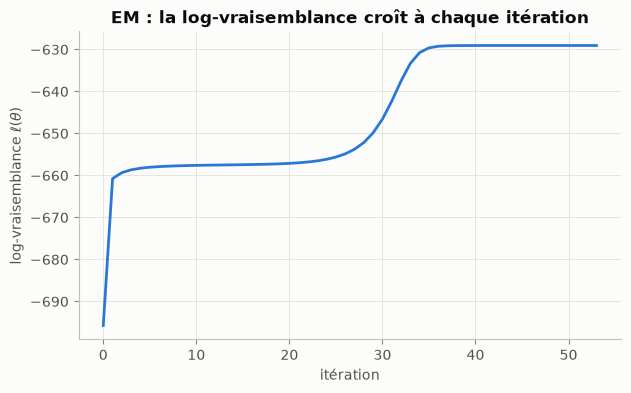

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(em_libre["loglik"], color=BLUE)
ax.set_xlabel("itération")
ax.set_ylabel("log-vraisemblance $\\ell(\\theta)$")
ax.set_title("EM : la log-vraisemblance croît à chaque itération")
plt.show()

In [7]:
lab_km, C_km, _ = ns.kmeans(Xe, 3, centres_init=mu0)
for s in (1.0, 0.5, 0.2, 0.05):
    em = ns.em_melange_isotrope(Xe, 3, sigma2=s ** 2, mu_init=mu0, n_iter=500)
    durete = em["resp"].max(1).mean()
    ecart = np.abs(np.sort(em["mu"], 0) - np.sort(C_km, 0)).max()
    print("sigma = %.2f : max_k gamma_ik moyen = %.3f, |mu_EM - centres K-means| max = %.3f"
          % (s, durete, ecart))

sigma = 1.00 : max_k gamma_ik moyen = 0.885, |mu_EM - centres K-means| max = 0.165
sigma = 0.50 : max_k gamma_ik moyen = 0.981, |mu_EM - centres K-means| max = 0.034
sigma = 0.20 : max_k gamma_ik moyen = 0.998, |mu_EM - centres K-means| max = 0.008
sigma = 0.05 : max_k gamma_ik moyen = 1.000, |mu_EM - centres K-means| max = 0.000


Quand $\sigma$ diminue, les responsabilités deviennent 0 ou 1 et les centres d'EM rejoignent
ceux des K-means. Visualisons la responsabilité du groupe le plus probable.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, s in zip(axes, (1.0, 0.5, 0.05)):
    em = ns.em_melange_isotrope(Xe, 3, sigma2=s ** 2, mu_init=mu0, n_iter=500)
    sc = ax.scatter(*Xe.T, c=em["resp"].max(1), cmap=SEQ, vmin=0.33, vmax=1, s=14)
    ax.scatter(*em["mu"].T, marker="X", s=120, color=ORANGE, edgecolor="k")
    ax.set_title("$\\sigma = %.2f$" % s)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
plt.colorbar(sc, ax=axes, label="$\\max_k \\gamma_{ik}$")
plt.show()

> **À retenir.** Pour un mélange gaussien isotrope, EM alterne responsabilités (étape E) et
> moyennes/proportions/variance pondérées (étape M). Quand $\sigma \to 0$, les responsabilités
> deviennent des affectations dures au centre le plus proche : on retrouve exactement les deux
> étapes des K-means.

## Exercice 14.3 : CART et PRIM avec la référence « produit des marginales »

**Énoncé.** La section 14.2.6 propose d'utiliser CART ou PRIM pour construire des règles
d'association généralisées. Montrer qu'un problème survient avec ces deux méthodes lorsque les
données de référence sont tirées de la loi **produit des marginales**, c'est-à-dire en permutant
aléatoirement les valeurs de chaque variable. Proposer des moyens de contourner ce problème.